In [1]:
import pandas as pd, numpy as np

df = pd.read_csv("diabetes_young_adults.csv")
target = "Diabetes_binary"

binary_cols = ["HighBP","HighChol","CholCheck","Smoker","Stroke","HeartDiseaseorAttack",
               "PhysActivity","Fruits","Veggies","HvyAlcoholConsump","AnyHealthcare",
               "NoDocbcCost","DiffWalk","Sex", target]
for c in binary_cols:
    assert set(df[c].unique()) <= {0.0, 1.0}, f"{c} has unexpected values"
print("Binary columns OK")

print("Missing values:", df.isnull().sum().sum())
print(df[["BMI","MentHlth","PhysHlth","GenHlth","Education","Income","Age"]].agg(["min","max"]).T)

Binary columns OK
Missing values: 0
            min   max
BMI        13.0  98.0
MentHlth    0.0  30.0
PhysHlth    0.0  30.0
GenHlth     1.0   5.0
Education   1.0   6.0
Income      1.0   8.0
Age         1.0   3.0


In [2]:
df = df.astype({c: int for c in df.columns if c != "BMI"})
df.dtypes.value_counts()

int64      21
float64     1
Name: count, dtype: int64

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Positives  train:", y_train.sum(), " test:", y_test.sum())
print("Positive rate  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))

pd.concat([X_train, y_train], axis=1).to_csv("train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv("test.csv", index=False)

Train: (19536, 21)  Test: (4885, 21)
Positives  train: 426  test: 106
Positive rate  train: 0.0218  test: 0.0217


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

num_cols = ["BMI", "MentHlth", "PhysHlth"]
cat_idx = [i for i, c in enumerate(X_train.columns) if c not in num_cols]

models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))]),
    "KNN": ImbPipeline([
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),
        ("scale", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15))]),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        min_samples_leaf=5, n_jobs=-1, random_state=42),
    "SVM": Pipeline([
        ("scale", StandardScaler()),
        ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=42))]),
}

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(models["Logistic Regression"], X_train, y_train,
                         cv=cv, scoring="roc_auc")
print("LR ROC-AUC per fold:", scores.round(3), " mean:", scores.mean().round(3))

models["KNN"].fit(X_train, y_train)  
print("KNN pipeline OK")

LR ROC-AUC per fold: [0.801 0.785 0.801 0.825 0.834]  mean: 0.809
KNN pipeline OK


In [6]:
import time, joblib
import pandas as pd, numpy as np
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

print(list(models.keys()))
print(X_train.shape, X_test.shape)

['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVM']
(19536, 21) (4885, 21)


In [13]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.001, 0.003, 0.01, 0.03, 0.1]},
    "KNN": {"clf__n_neighbors": [31, 51, 101, 201], "clf__weights": ["uniform", "distance"]},
    "Decision Tree": {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [50, 100, 200]},
    "Random Forest": {"max_depth": [3, 4, 6], "min_samples_leaf": [20, 50, 100]},
    "SVM": {"clf__C": [0.01, 0.03, 0.1, 0.3]},
}

In [14]:
cv5 = cv  # stratified 5-fold from step 3.7
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)   

searches, rows = {}, []
for name, grid in param_grids.items():
    t0 = time.time()
    gs = GridSearchCV(models[name], grid, scoring="roc_auc",
                      cv=cv3 if name == "SVM" else cv5,
                      n_jobs=1 if name == "Random Forest" else -1,
                      refit=True, verbose=1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    rows.append({"Model": name, "Best params": gs.best_params_,
                 "CV ROC-AUC": round(gs.best_score_, 4),
                 "Folds": gs.cv.n_splits, "Time (s)": round(time.time() - t0)})
    print(f"{name}: {gs.best_params_}  AUC={gs.best_score_:.4f}  ({time.time()-t0:.0f}s)")

tuning = pd.DataFrame(rows)
tuning.to_csv("tuning_results.csv", index=False)
best_models = {n: gs.best_estimator_ for n, gs in searches.items()}
joblib.dump(best_models, "best_models.joblib")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Logistic Regression: {'clf__C': 0.001}  AUC=0.8112  (19s)
Fitting 5 folds for each of 8 candidates, totalling 40 fits
KNN: {'clf__n_neighbors': 201, 'clf__weights': 'distance'}  AUC=0.6951  (53s)
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Decision Tree: {'max_depth': 3, 'min_samples_leaf': 200}  AUC=0.7738  (1s)
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Random Forest: {'max_depth': 6, 'min_samples_leaf': 100}  AUC=0.8042  (54s)
Fitting 3 folds for each of 4 candidates, totalling 12 fits
SVM: {'clf__C': 0.03}  AUC=0.7997  (63s)


['best_models.joblib']

In [15]:
print(tuning.to_string(index=False))

              Model                                           Best params  CV ROC-AUC  Folds  Time (s)
Logistic Regression                                     {'clf__C': 0.001}      0.8112      5        19
                KNN {'clf__n_neighbors': 201, 'clf__weights': 'distance'}      0.6951      5        53
      Decision Tree             {'max_depth': 3, 'min_samples_leaf': 200}      0.7738      5         1
      Random Forest             {'max_depth': 6, 'min_samples_leaf': 100}      0.8042      5        54
                SVM                                      {'clf__C': 0.03}      0.7997      3        63


In [16]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, est in best_models.items():
    r = cross_validate(est, X_train, y_train, cv=cv5, scoring=scoring,
                       n_jobs=1 if name == "Random Forest" else -1)
    cv_rows.append({"Model": name,
                    **{m: f"{r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}" for m in scoring}})

cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv("cv_results.csv", index=False)
print(cv_table.to_string(index=False))

              Model      accuracy     precision        recall            f1       roc_auc
Logistic Regression 0.780 ± 0.004 0.067 ± 0.006 0.700 ± 0.065 0.122 ± 0.011 0.811 ± 0.017
                KNN 0.739 ± 0.016 0.042 ± 0.004 0.507 ± 0.055 0.078 ± 0.007 0.695 ± 0.016
      Decision Tree 0.803 ± 0.094 0.073 ± 0.020 0.587 ± 0.076 0.128 ± 0.032 0.774 ± 0.026
      Random Forest 0.810 ± 0.006 0.073 ± 0.007 0.655 ± 0.058 0.131 ± 0.013 0.804 ± 0.027
                SVM 0.760 ± 0.007 0.061 ± 0.004 0.697 ± 0.044 0.113 ± 0.008 0.798 ± 0.025


In [17]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

def get_scores(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

test_rows, preds, probs = [], {}, {}
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_score = get_scores(model, X_test)
    preds[name], probs[name] = y_pred, y_score
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    test_rows.append({"Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "PR-AUC": average_precision_score(y_test, y_score),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn})

results = pd.DataFrame(test_rows).round(3)
results.to_csv("results.csv", index=False)
joblib.dump({"preds": preds, "probs": probs}, "test_predictions.joblib")
print(results.to_string(index=False))

              Model  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC  TP   FP  FN   TN
Logistic Regression     0.778      0.070   0.755 0.128    0.830   0.194  80 1060  26 3719
                KNN     0.754      0.049   0.557 0.089    0.736   0.079  59 1155  47 3624
      Decision Tree     0.831      0.078   0.632 0.139    0.786   0.088  67  789  39 3990
      Random Forest     0.815      0.084   0.755 0.151    0.829   0.178  80  877  26 3902
                SVM     0.755      0.067   0.792 0.123    0.840   0.155  84 1177  22 3602


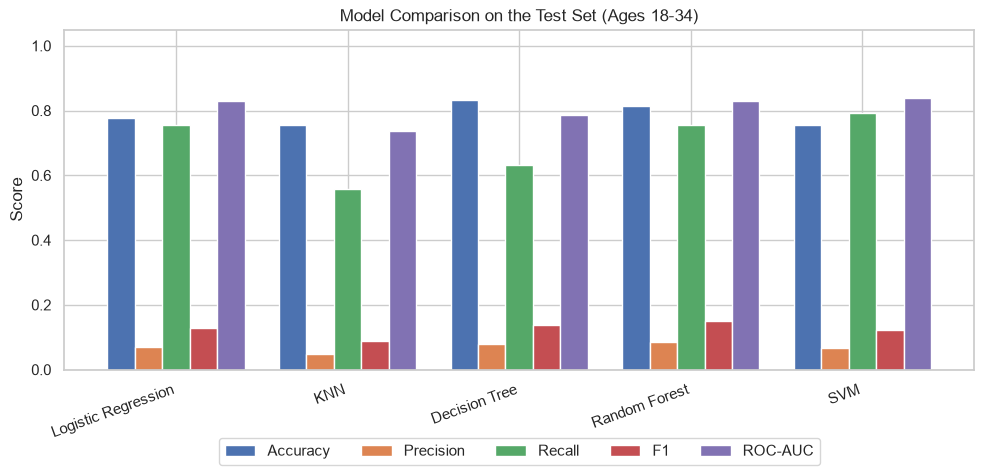

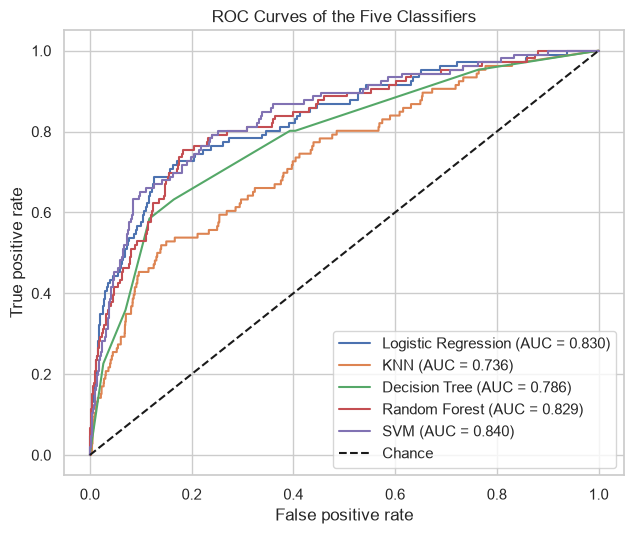

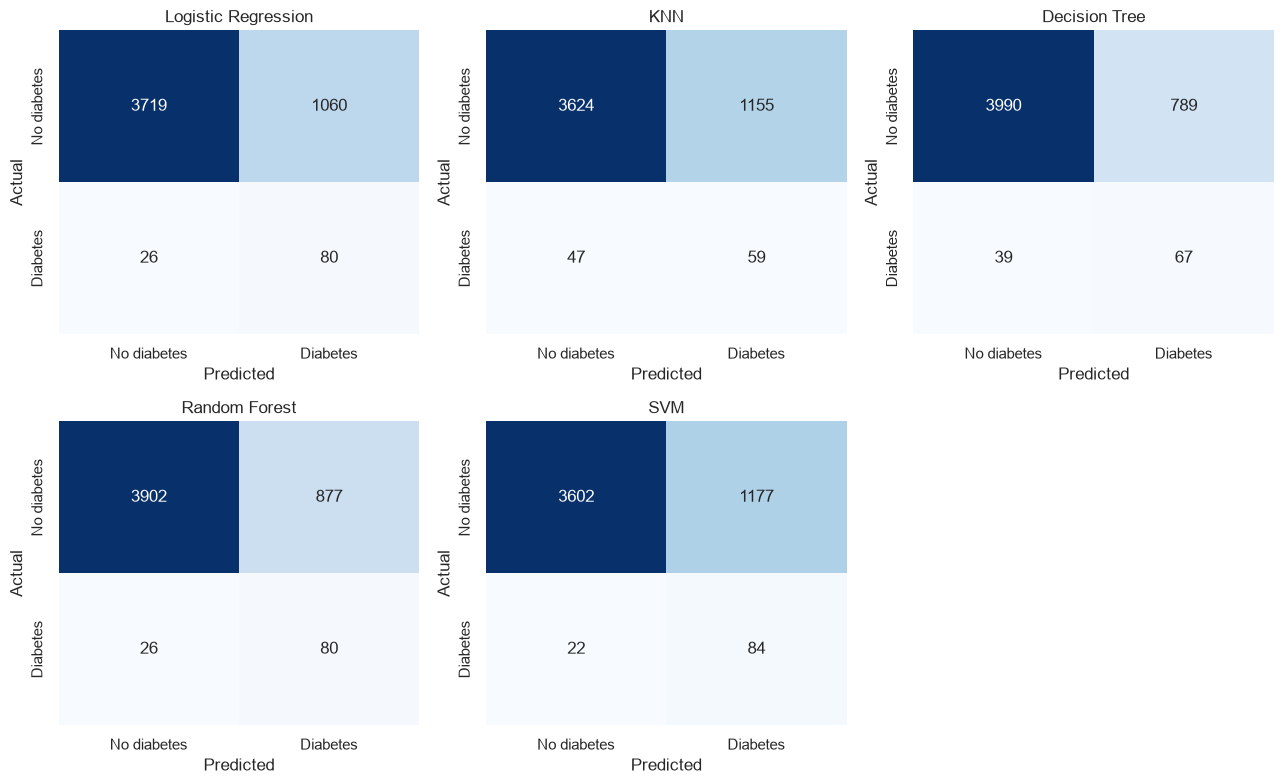

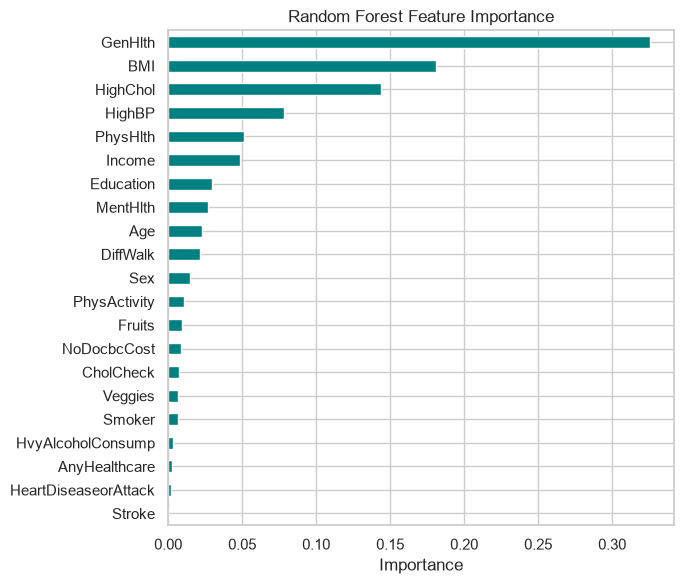

In [18]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve
sns.set_theme(style="whitegrid")

# (a) Metric comparison
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ax = results.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 5), width=0.8)
ax.set_title("Model Comparison on the Test Set (Ages 18-34)")
ax.set_ylabel("Score"); ax.set_xlabel(""); ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5)
plt.tight_layout(); plt.savefig("figures/09_metric_comparison.png", dpi=300); plt.show()

# (b) ROC curves
plt.figure(figsize=(6.5, 5.5))
for name in probs:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC Curves of the Five Classifiers"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/10_roc_curves.png", dpi=300); plt.show()

# (c) Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, name in zip(axes.ravel(), preds):
    sns.heatmap(confusion_matrix(y_test, preds[name]), annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax, xticklabels=["No diabetes", "Diabetes"],
                yticklabels=["No diabetes", "Diabetes"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("figures/11_confusion_matrices.png", dpi=300); plt.show()

# (d) Random Forest feature importance
imp = pd.Series(best_models["Random Forest"].feature_importances_,
                index=X_train.columns).sort_values()
plt.figure(figsize=(7, 6))
imp.plot(kind="barh", color="teal")
plt.title("Random Forest Feature Importance"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("figures/12_rf_feature_importance.png", dpi=300); plt.show()

In [19]:
import sys, sklearn, imblearn, pandas, numpy, matplotlib, seaborn, joblib
print("Python", sys.version.split()[0])
for m in [sklearn, imblearn, pandas, numpy, matplotlib, seaborn, joblib]:
    print(m.__name__, m.__version__)

Python 3.13.4
sklearn 1.9.1
imblearn 0.14.2
pandas 3.0.6
numpy 2.5.3
matplotlib 3.11.2
seaborn 0.13.2
joblib 1.6.0


In [20]:
import time
from sklearn.base import clone

rows = []
for name, est in best_models.items():
    m = clone(est)
    t0 = time.perf_counter(); m.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); m.predict(X_test); pred_s = time.perf_counter() - t0
    rows.append({"Model": name, "Train time (s)": round(fit_s, 2), "Predict time (s)": round(pred_s, 3)})
timing = pd.DataFrame(rows)
timing.to_csv("timing.csv", index=False)
print(timing.to_string(index=False))

              Model  Train time (s)  Predict time (s)
Logistic Regression            0.29             0.020
                KNN            3.74             0.553
      Decision Tree            0.03             0.002
      Random Forest            1.05             0.060
                SVM           15.39             6.038
